# 📉 Superstore Demand Forecasting — SARIMA
**Tools:** Python · Pandas · statsmodels · Matplotlib  
**Goal:** Fit a SARIMA model per series on the 36 training months, score it on the 12 holdout months (Jan–Dec 2017), and compare it with the seasonal naive benchmark and Holt-Winters.

---

| Section | Question it answers |
|---|---|
| 1. Setup | Which data is the model allowed to see? |
| 2. Differencing | How much differencing does each series need? |
| 3. Model selection | Which SARIMA orders does the training data choose? |
| 4. Holdout results | Does SARIMA beat the benchmark and Holt-Winters? |
| 5. Confidence intervals | Do the 95% intervals contain the actual sales? |
| 6. Total: direct or bottom-up? | Is Total better forecast directly or as the sum of the categories? |
| 7. Findings | Which model should produce the final forecast? |

---
## 1. SETUP
> **Goal:** Load the series, split off the holdout, and load the seasonal naive and Holt-Winters holdout forecasts saved by notebook 02, so all models are compared on exactly the same months.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from src.config import HOLDOUT_MONTHS, OUTPUTS_DIR
from src.forecasting.metrics import mape, wape
from src.forecasting.sarima import (
    KPSS_ALPHA, SEASONAL_STRENGTH_THRESHOLD, choose_differencing, choose_seasonal_differencing,
    kpss_pvalue, seasonal_strength, select_sarima,
)
from src.forecasting.series import CATEGORIES, SERIES, TOTAL, load_monthly_sales, split_holdout
from src.plotting import AXIS, INK, MUTED, SERIES_COLORS, apply_style, thousands

apply_style()

TABLES_DIR = OUTPUTS_DIR / "forecasting" / "tables"
FIGURES_DIR = OUTPUTS_DIR / "forecasting" / "figures"

sales = load_monthly_sales()
train, holdout = split_holdout(sales)

saved = pd.read_csv(TABLES_DIR / "holdout_forecasts.csv", index_col=["model", "month"], parse_dates=["month"])
earlier_models = {model: saved.loc[model].reindex(holdout.index) for model in ["Seasonal naive", "Holt-Winters"]}

print(f"Train   : {len(train)} months  ({train.index.min():%b %Y} → {train.index.max():%b %Y})")
print(f"Holdout : {len(holdout)} months  ({holdout.index.min():%b %Y} → {holdout.index.max():%b %Y})")
print(f"Loaded holdout forecasts for: {', '.join(earlier_models)}")

Train   : 36 months  (Jan 2014 → Dec 2016)
Holdout : 12 months  (Jan 2017 → Dec 2017)
Loaded holdout forecasts for: Seasonal naive, Holt-Winters


---
## 2. DIFFERENCING
> **Goal:** Fix how many times each series is differenced before SARIMA models it.

SARIMA is written **SARIMA(p, d, q)(P, D, Q)₁₂**. `d` and `D` cannot be chosen by AICc like the other orders: differencing changes the data the model is fitted to, so AICc values with different `d` or `D` are not comparable. The stationarity tests in the exploration notebook were inconclusive, so the differencing follows the rules used by `auto.arima` (Hyndman & Khandakar, 2008), implemented in `src/forecasting/sarima.py`:

| Order | Rule |
|---|---|
| **D** (seasonal difference) | D = 1 when the STL seasonal strength is above 0.64 |
| **d** (first difference) | d = 1 when KPSS rejects stationarity (p < 0.05) of the series, after the seasonal difference if D = 1 |

In [2]:
rules = {}
for name in SERIES:
    D = choose_seasonal_differencing(train[name])
    tested = train[name].diff(12).dropna() if D else train[name]
    rules[name] = {
        "seasonal_strength": seasonal_strength(train[name]),
        "D": D,
        "kpss_p": kpss_pvalue(tested),
        "d": choose_differencing(train[name], D),
    }

differencing = pd.DataFrame(rules).T.astype({"D": int, "d": int})
print(f"D = 1 when seasonal strength > {SEASONAL_STRENGTH_THRESHOLD};  d = 1 when KPSS p < {KPSS_ALPHA}")
differencing.style.format({"seasonal_strength": "{:.2f}", "kpss_p": "{:.3f}"})

D = 1 when seasonal strength > 0.64;  d = 1 when KPSS p < 0.05


,seasonal_strength,D,kpss_p,d
Total,0.87,1,0.023,1
Furniture,0.90,1,0.100,0
Office Supplies,0.65,1,0.073,0
Technology,0.57,0,0.040,1


---
## 3. MODEL SELECTION
> **Goal:** With `d` and `D` fixed, try every combination of `p, q, P, Q` ∈ {0, 1}, with and without a trend term, and keep the lowest AICc. All on the training months.

The trend term depends on how much differencing is applied:

| Differencing | Trend options | Meaning |
|---|---|---|
| none | none · constant | sales vary around a fixed level |
| d + D = 1 | none · **drift** | a drift adds steady growth: the same increase every period |
| d + D = 2 | none | a trend term would not be identifiable |

In [3]:
selected, candidates = {}, {}
for name in SERIES:
    selected[name], candidates[name] = select_sarima(train[name])

TREND_LABELS = {"n": "none", "c": "constant", "t": "drift"}

def describe(result):
    (p, d, q), (P, D, Q, s) = result.model.order, result.model.seasonal_order
    return f"SARIMA({p},{d},{q})({P},{D},{Q})[{s}]"

chosen = pd.DataFrame({
    name: {
        "model": describe(result),
        "trend": TREND_LABELS[result.model.trend],
        "aicc": result.aicc,
        "candidates_tried": len(candidates[name]),
    }
    for name, result in selected.items()
}).T
chosen.style.format({"aicc": "{:.1f}"})

,model,trend,aicc,candidates_tried
Total,"SARIMA(1,1,0)(0,1,1)[12]",none,506.2,16
Furniture,"SARIMA(0,0,0)(1,1,0)[12]",drift,473.0,32
Office Supplies,"SARIMA(1,0,0)(0,1,1)[12]",drift,485.8,32
Technology,"SARIMA(0,1,1)(1,0,0)[12]",drift,745.4,32


The three best candidates per series. Close AICc values (within about 2) mean the data cannot really tell those models apart.

In [4]:
top = pd.concat({name: table.head(3) for name, table in candidates.items()}, names=["series", "rank"])
top["trend"] = top["trend"].map(TREND_LABELS)
top["aicc_vs_best"] = top["aicc"] - top.groupby(level="series")["aicc"].transform("min")
top.round(1)

order seasonal_order  trend   aicc  aicc_vs_best
series          rank                                                      
Total           0     (1, 1, 0)  (0, 1, 1, 12)   none  506.2           0.0
                1     (0, 1, 1)  (0, 1, 1, 12)   none  506.2           0.1
                2     (0, 1, 0)  (0, 1, 1, 12)   none  506.8           0.6
Furniture       0     (0, 0, 0)  (1, 1, 0, 12)  drift  473.0           0.0
                1     (0, 0, 0)  (0, 1, 1, 12)  drift  473.6           0.6
                2     (0, 0, 0)  (0, 1, 0, 12)  drift  474.7           1.7
Office Supplies 0     (1, 0, 0)  (0, 1, 1, 12)  drift  485.8           0.0
                1     (0, 0, 0)  (0, 1, 1, 12)  drift  486.5           0.7
                2     (0, 0, 0)  (1, 1, 0, 12)  drift  487.1           1.3
Technology      0     (0, 1, 1)  (1, 0, 0, 12)  drift  745.4           0.0
                1     (0, 1, 1)  (0, 0, 0, 12)  drift  745.7           0.4
                2     (0, 1, 1)  (1, 0, 0, 12)   none  746.3           1.0

---
## 4. HOLDOUT RESULTS
> **Goal:** Score the SARIMA forecasts on the 12 holdout months and compare them with the earlier models.

### 4.1 — MAPE, WAPE and Bias

In [5]:
sarima_forecasts = {name: result.get_forecast(HOLDOUT_MONTHS) for name, result in selected.items()}
sarima_mean = pd.DataFrame({name: fc.predicted_mean for name, fc in sarima_forecasts.items()})
models = {**earlier_models, "SARIMA": sarima_mean}

def bias(actual, forecast):
    """Total forecast vs total actual, in %: negative = forecast too low."""
    return (forecast.sum() / actual.sum() - 1) * 100

comparison = pd.concat({
    model: pd.DataFrame({
        name: {
            "WAPE": wape(holdout[name], forecast[name]),
            "MAPE": mape(holdout[name], forecast[name]),
            "bias": bias(holdout[name], forecast[name]),
        }
        for name in SERIES
    }).T
    for model, forecast in models.items()
}, axis=1)
comparison.index.name = "series"
comparison.to_csv(TABLES_DIR / "model_comparison.csv")
comparison.round(1)

Seasonal naive             Holt-Winters             SARIMA  \
                          WAPE  MAPE  bias         WAPE  MAPE  bias   WAPE   
series                                                                       
Total                     25.3  24.5 -16.9         22.5  23.3 -20.0   24.7   
Furniture                 20.9  24.0  -7.7         23.8  32.4  -9.9   19.8   
Office Supplies           35.9  32.1 -25.3         29.2  28.6 -25.8   29.3   
Technology                34.6  41.4 -16.7         33.5  31.9 -25.4   32.3   

                             
                 MAPE  bias  
series                       
Total            33.6  17.4  
Furniture        28.4   7.6  
Office Supplies  32.4 -13.0  
Technology       46.3   1.6

In [6]:
wape_only = comparison.xs("WAPE", axis=1, level=1).copy()
wape_only["best model"] = wape_only.idxmin(axis=1)
wape_only["SARIMA beats seasonal naive?"] = wape_only["SARIMA"] < wape_only["Seasonal naive"]
wape_only.round(1)

,Seasonal naive,Holt-Winters,SARIMA,best model,SARIMA beats seasonal naive?
series,,,,,
Total,25.3,22.5,24.7,Holt-Winters,True
Furniture,20.9,23.8,19.8,SARIMA,True
Office Supplies,35.9,29.2,29.3,Holt-Winters,True
Technology,34.6,33.5,32.3,SARIMA,True


### 4.2 — SARIMA Forecasts with 95% Intervals

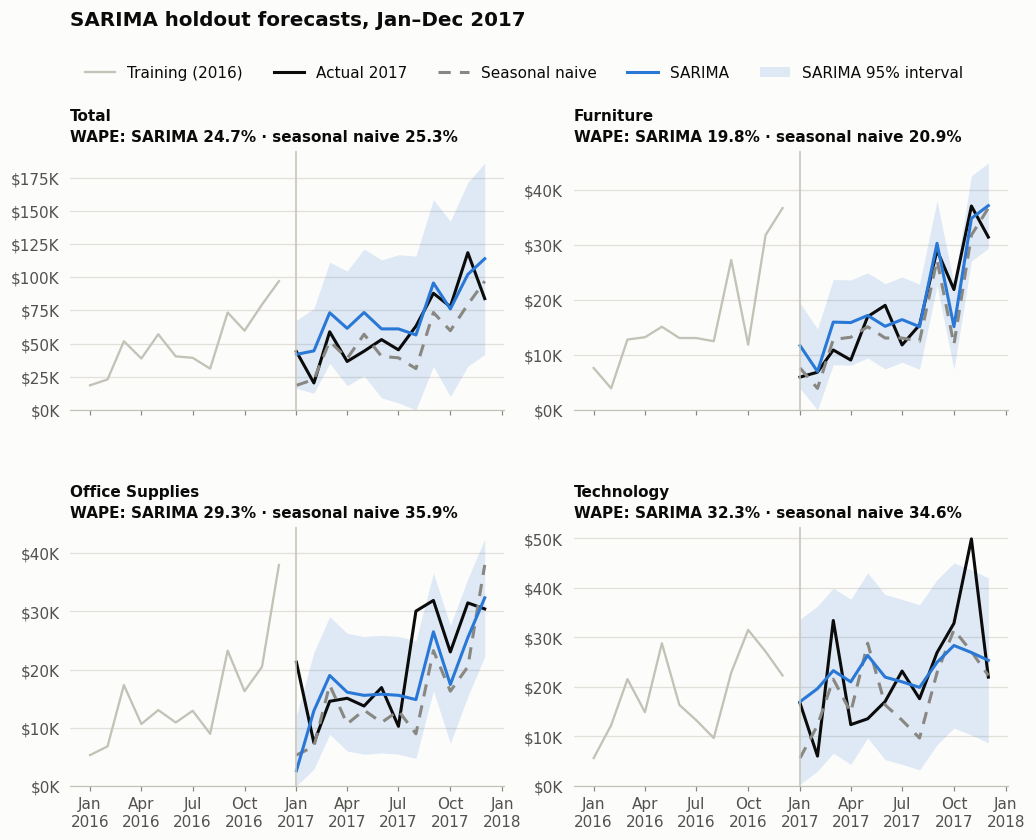

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), sharex=True, gridspec_kw={"hspace": 0.45, "wspace": 0.16})
context = train.loc["2016"]
sarima_color = SERIES_COLORS["Furniture"]

for ax, name in zip(axes.flat, SERIES):
    interval = sarima_forecasts[name].conf_int(alpha=0.05)
    ax.fill_between(holdout.index, interval.iloc[:, 0].clip(lower=0), interval.iloc[:, 1],
                    color=sarima_color, alpha=0.14, linewidth=0, label="SARIMA 95% interval")
    ax.plot(context.index, context[name], color=AXIS, linewidth=1.5, label="Training (2016)")
    ax.plot(holdout.index, holdout[name], color=INK, label="Actual 2017")
    ax.plot(holdout.index, models["Seasonal naive"][name], color=MUTED, linestyle=(0, (4, 3)), label="Seasonal naive")
    ax.plot(holdout.index, sarima_mean[name], color=sarima_color, label="SARIMA")
    ax.axvline(holdout.index[0], color=AXIS, linewidth=1)

    sarima_wape = comparison.loc[name, ("SARIMA", "WAPE")]
    naive_wape = comparison.loc[name, ("Seasonal naive", "WAPE")]
    ax.set_title(f"{name}\nWAPE: SARIMA {sarima_wape:.1f}% · seasonal naive {naive_wape:.1f}%", fontsize=10, linespacing=1.5)
    ax.set_ylim(0, None)
    ax.yaxis.set_major_formatter(thousands)

for ax in axes[-1]:
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b\n%Y"))

handles, labels = axes[0, 0].get_legend_handles_labels()
order = [1, 2, 3, 4, 0]
fig.legend([handles[i] for i in order], [labels[i] for i in order], loc="upper center", bbox_to_anchor=(0.5, 1.0), ncol=5)
fig.suptitle("SARIMA holdout forecasts, Jan–Dec 2017", x=0.125, ha="left", fontsize=13, fontweight="bold", y=1.05)
fig.savefig(FIGURES_DIR / "07_sarima_holdout_forecasts.png")
plt.show()

---
## 5. CONFIDENCE INTERVALS
> **Goal:** Check whether the 95% intervals are honest. If they are, about 95% of actual months (11–12 of 12) should fall inside them. Fewer means the intervals are too narrow; all of them with very wide bands means they are too cautious to be useful for planning.

In [8]:
coverage = {}
for name in SERIES:
    interval = sarima_forecasts[name].conf_int(alpha=0.05)
    lower, upper = interval.iloc[:, 0], interval.iloc[:, 1]
    inside = (holdout[name] >= lower) & (holdout[name] <= upper)
    coverage[name] = {
        "months_inside": int(inside.sum()),
        "months_outside": ", ".join(f"{m:%b}" for m in holdout.index[~inside]) or "—",
        "avg_width_vs_actual": ((upper - lower) / holdout[name]).mean(),
        "months_with_lower_bound_below_0": int((lower < 0).sum()),
    }

coverage = pd.DataFrame(coverage).T
coverage.style.format({"avg_width_vs_actual": "{:.0%}"})

,months_inside,months_outside,avg_width_vs_actual,months_with_lower_bound_below_0
Total,12,—,187%,1
Furniture,12,—,118%,1
Office Supplies,10,"Jan, Aug",121%,1
Technology,11,Nov,195%,0


`avg_width_vs_actual` is the interval's width as a share of the actual sales that month: 150% means the band spans one and a half times the month's sales. A lower bound below \$0 is impossible for sales; the chart cuts the band at zero.

---
## 6. TOTAL: DIRECT OR BOTTOM-UP?
> **Goal:** Total can be forecast in two ways: with its own model (above), or by adding up the three category forecasts ("bottom-up"). The bottom-up total is automatically consistent with the category plans, which matters for inventory.

In [9]:
total_options = {
    "Direct SARIMA on Total": sarima_mean[TOTAL],
    "Sum of category SARIMAs": sarima_mean[CATEGORIES].sum(axis=1),
}
pd.DataFrame({
    label: {
        "WAPE": wape(holdout[TOTAL], forecast),
        "MAPE": mape(holdout[TOTAL], forecast),
        "bias": bias(holdout[TOTAL], forecast),
    }
    for label, forecast in total_options.items()
}).T.round(1)

,WAPE,MAPE,bias
Direct SARIMA on Total,24.7,33.6,17.4
Sum of category SARIMAs,20.5,25.8,-1.5


---
## 7. FINDINGS

| # | Finding | Evidence (holdout, Jan–Dec 2017) |
|---|---|---|
| 1 | **SARIMA beats the seasonal naive benchmark on all four series.** | WAPE: Furniture 19.8% vs 20.9%, Office Supplies 29.3% vs 35.9%, Technology 32.3% vs 34.6%. On Total the gain is marginal: 24.7% vs 25.3%. |
| 2 | **The drift term largely fixes the under-forecast for the categories.** | AICc chose a drift (steady growth) for all three categories. Bias went from −10% to −26% with Holt-Winters to +7.6% (Furniture), −13.0% (Office Supplies) and +1.6% (Technology). |
| 3 | **The direct Total model overshoots.** | It is differenced twice (d = 1, D = 1), which projects the strong end of 2016 forward: +17.4% bias, with most of the excess in Jan–Aug. |
| 4 | **Adding up the category forecasts gives the best Total forecast of any model.** | Bottom-up WAPE 20.5% and bias −1.5%, against 22.5% for Holt-Winters and 24.7% for the direct SARIMA. |
| 5 | **The 95% intervals are honest but wide.** | 45 of 48 actual months fall inside them (94%, against 95% expected). The bands span 118–195% of the month's actual sales, and Technology's \\$50K November falls outside. |
| 6 | **The exact orders are uncertain; the choice of drift is not.** | The top three candidates of every series are within 2 AICc points of each other, so the data cannot separate, say, a seasonal AR from a seasonal MA term. The drift appears in nearly every top candidate for the categories. |

### Model for the final forecast

**SARIMA for each category, with Total as the sum of the three category forecasts.**

- **Furniture and Technology:** SARIMA has the lowest WAPE of all models.
- **Office Supplies:** SARIMA and Holt-Winters tie on WAPE (29.3% vs 29.2%), but SARIMA's bias is half as large (−13.0% vs −25.8%) and it provides confidence intervals.
- **Total:** the bottom-up sum is the most accurate Total forecast, and it guarantees that the category inventory plans add up to the company plan.

### Caveats
- **This comparison uses the holdout to choose between model families.** That makes the winning WAPE slightly optimistic. Within each family, every choice (orders, trend, Holt-Winters variant) was still made on the training months only.
- **WAPE and MAPE disagree for Technology and Total.** SARIMA's Technology MAPE is 46.3% against Holt-Winters' 31.9%: SARIMA misses more on the quiet months, where a small dollar error is a large percentage. WAPE, which weights the big months, is the metric that matters for inventory.
- **The bottom-up Total has no interval yet.** Category intervals cannot simply be added, because the categories' errors are correlated. The final forecast step needs a method for this, for example simulating the category forecasts together.

> **Next step:** refit SARIMA on all 48 months and forecast Jan–Jun 2018 with 95% intervals, then turn the forecast into inventory recommendations by category and month.